In [2]:
import pandas as pd
df = pd.read_csv("data/fitbit_devices_sold.csv")
df

,year,devices_sold_millions,source
0,2011,0.200,Fitbit S-1 (2015)
1,2012,1.300,Fitbit S-1 (2015)
2,2013,4.500,Fitbit S-1 (2015)
3,2014,10.900,Fitbit S-1 (2015); Fitbit FY2015 10-K
4,2015,21.400,Fitbit FY2015 10-K
5,2016,22.300,Fitbit FY2016 10-K
6,2017,15.343,Fitbit FY2019 10-K
7,2018,13.939,Fitbit FY2019 10-K
8,2019,15.988,Fitbit FY2019 10-K


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Bass model: cumulative adopters N(t) and period sales S(t) = N(t) - N(t-1)
def bass_cum(t, p, q, M):
    e = np.exp(-(p + q) * t)
    return M * (1 - e) / (1 + (q / p) * e)

def bass_sales(t, p, q, M):
    return bass_cum(t, p, q, M) - bass_cum(t - 1, p, q, M)

def fit_bass(t, y):
    popt, pcov = curve_fit(
        bass_sales, t, y,
        p0=(0.03, 0.4, y.sum() * 1.5),
        bounds=([1e-5, 1e-3, y.sum()], [1, 3, 2000]),
        maxfev=50000,
    )
    return popt, np.sqrt(np.diag(pcov))

def r_squared(y, pred):
    return 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()

results = {}
for n, label in [(6, "2011-2016"), (9, "2011-2019")]:
    t = np.arange(1, n + 1)
    y = df["devices_sold_millions"].values[:n]
    popt, se = fit_bass(t, y)
    results[label] = popt
    print(label)
    print(f"  p = {popt[0]:.4f} (se {se[0]:.4f})")
    print(f"  q = {popt[1]:.4f} (se {se[1]:.4f})")
    print(f"  M = {popt[2]:.1f} million (se {se[2]:.1f})")
    print(f"  R2 = {r_squared(y, bass_sales(t, *popt)):.3f}")

    

Matplotlib is building the font cache; this may take a moment.


2011-2016
  p = 0.0026 (se 0.0003)
  q = 1.2122 (se 0.0330)
  M = 80.4 million (se 1.8)
  R2 = 0.999
2011-2019
  p = 0.0118 (se 0.0067)
  q = 0.6746 (se 0.1385)
  M = 121.7 million (se 16.7)
  R2 = 0.821


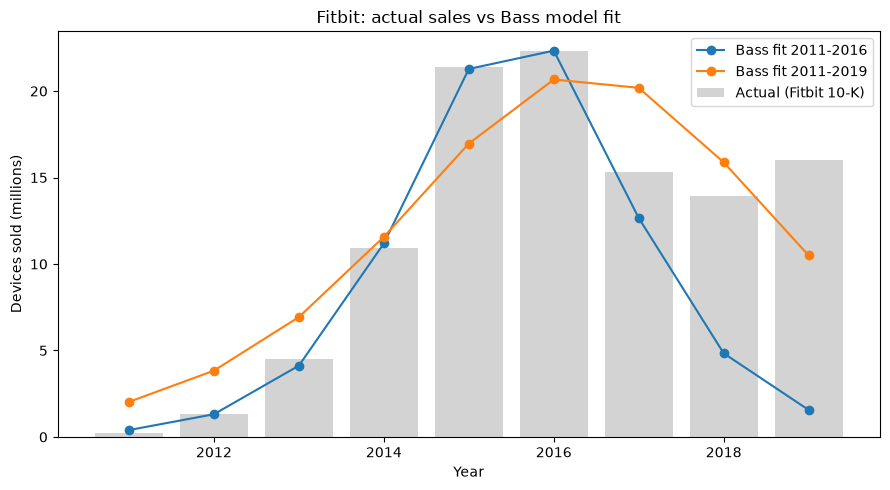

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
years = df["year"].values
ax.bar(years, df["devices_sold_millions"], color="lightgray", label="Actual (Fitbit 10-K)")
tt = np.arange(1, 10)
for label, popt in results.items():
    ax.plot(years, bass_sales(tt, *popt), marker="o", label=f"Bass fit {label}")
ax.set_xlabel("Year")
ax.set_ylabel("Devices sold (millions)")
ax.set_title("Fitbit: actual sales vs Bass model fit")
ax.legend()
plt.tight_layout()
plt.savefig("img/fitbit_bass_fit.png", dpi=200)
plt.show()

In [5]:
   params = pd.DataFrame(results, index=["p", "q", "M_millions"]).T
   params.to_csv("data/fitbit_bass_parameters.csv")
   params

,p,q,M_millions
2011-2016,0.002552,1.212211,80.373692
2011-2019,0.011790,0.674576,121.703258


A (Fitbit 2011-2016) takeoff year: 2022.65
B (Fitbit 2011-2019) takeoff year: 2022.65


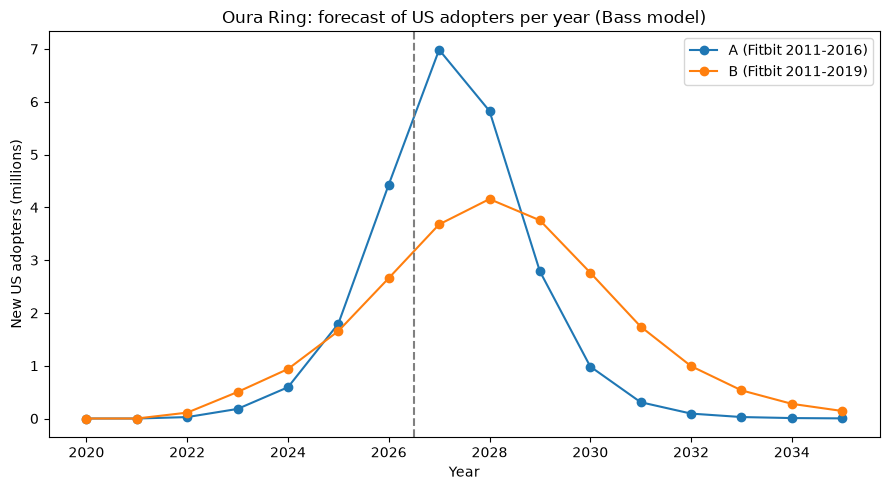

,scenario,year,new_adopters_M,cumulative_M
0,A (Fitbit 2011-2016),2020,0.00,0.00
1,A (Fitbit 2011-2016),2021,0.00,0.00
2,A (Fitbit 2011-2016),2022,0.03,0.03
3,A (Fitbit 2011-2016),2023,0.18,0.21
4,A (Fitbit 2011-2016),2024,0.59,0.80
5,A (Fitbit 2011-2016),2025,1.80,2.60
6,A (Fitbit 2011-2016),2026,4.43,7.03
7,A (Fitbit 2011-2016),2027,6.98,14.01
8,A (Fitbit 2011-2016),2028,5.83,19.84
9,A (Fitbit 2011-2016),2029,2.79,22.62


In [6]:
US_ADULTS_M = 260.0          # US Census Bureau (verify and cite)
SMARTWATCH_SHARE = 0.37      # Pew Research Center, Feb 2026
RING_CONVERSION = 0.25       # assumption (test 0.15 and 0.35 as sensitivity)
M_US = US_ADULTS_M * SMARTWATCH_SHARE * RING_CONVERSION

OURA_TOTAL_RINGS_M = 5.5     # rings sold by June 2026 (verify in Oura S-1)
US_SHARE = 0.80              # ~80% of hardware sales are in the US (verify in S-1)
OBSERVED_US_CUM = OURA_TOTAL_RINGS_M * US_SHARE
OBS_DATE = 2026.5

from scipy.optimize import brentq

def bass_cum_t(t, p, q, M):
    t = np.maximum(t, 0)
    e = np.exp(-(p + q) * t)
    return M * (1 - e) / (1 + (q / p) * e)

scenarios = {"A (Fitbit 2011-2016)": results["2011-2016"],
             "B (Fitbit 2011-2019)": results["2011-2019"]}

years = np.arange(2020, 2036)
frames = []
for name, (p, q, _) in scenarios.items():
    t_start = brentq(lambda s: bass_cum_t(OBS_DATE - s, p, q, M_US) - OBSERVED_US_CUM,
                     2000, OBS_DATE - 0.01)
    cum_end = bass_cum_t(years + 1.0 - t_start, p, q, M_US)
    cum_prev = bass_cum_t(years - t_start, p, q, M_US)
    frames.append(pd.DataFrame({"scenario": name, "year": years,
                                "new_adopters_M": cum_end - cum_prev,
                                "cumulative_M": cum_end}))
    print(name, "takeoff year:", round(t_start, 2))

forecast = pd.concat(frames)
forecast.to_csv("data/oura_us_forecast.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
for name, d in forecast.groupby("scenario"):
    ax.plot(d["year"], d["new_adopters_M"], marker="o", label=name)
ax.axvline(2026.5, ls="--", color="gray")
ax.set_xlabel("Year")
ax.set_ylabel("New US adopters (millions)")
ax.set_title("Oura Ring: forecast of US adopters per year (Bass model)")
ax.legend()
plt.tight_layout()
plt.savefig("img/oura_us_forecast.png", dpi=200)
plt.show()
forecast.round(2)